# Assignment 4 — Volatility surface and numerical Greeks
Student ID: **83019cd** · Group 2 · 15 points

We extend the lecture pricing library with three finite difference schemes and two bump conventions, compare numerical delta and gamma with their analytic values, and investigate suitable bump sizes.

## Starting point and assumptions
The local library is copied from `Lectures/2026_fall_BME/06_FlatVol/solution` (contract and enums from the parent lecture folder). Relative imports and the market-data path are adapted to this homework folder. Earlier Group 1 files and shared `src` are unchanged.

Primary reference: `06_FlatVol/notebook_flatvol.ipynb`, cells 23–26. Difference formulas: `Lectures/2026_spring_ELTE/07_part1_Finite_method_intro/Finite_difference_method_intro_SOLUTION.ipynb`, cells 17–22. Analytic BSM Greeks and pricing-library structure come from the BSM and BuildingBlocks lectures.

We assume no dividends, positive remaining maturity and volatility, and constant interest rate. FlatVol reads volatility at fixed strike and expiry (sticky strike); spot bumps do not move this coordinate. BSVol fixes volatility at its reference ATM strike and one-year expiry. Thus analytic and numerical Greeks differentiate the same price function.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'src').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the QuantCourseBP repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Student ID starts with digits, so use importlib rather than a dotted import statement.
import importlib
pricing = importlib.import_module('homeworks.83019cd.assignment_4.pricer')
for name in ['MarketData', 'FlatVolModel', 'BSVolModel', 'EuropeanContract',
             'EuropeanAnalyticPricer', 'Params', 'Stock', 'PutCallFwd', 'LongShort',
             'GreekMethod', 'FiniteDifferenceMethod', 'BumpType', 'Pricer']:
    globals()[name] = getattr(pricing, name)
MarketData.initialize()
output = root / 'homeworks/83019cd/assignment_4/figures'
output.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})


## Formulas and configuration
Write $f(S)$ for fair value and let $h>0$ be the **effective spot increment**.

- Absolute bump: $h=b_{abs}$ in spot currency units.
- Relative bump: $h=b_{rel}S$, where $b_{rel}$ is a dimensionless fraction of the original spot. The same $h$ is used at every point in a stencil.

Forward:
$$\Delta_h=\frac{f(S+h)-f(S)}h,\qquad
\Gamma_h=\frac{f(S+2h)-2f(S+h)+f(S)}{h^2}.$$
Backward:
$$\Delta_h=\frac{f(S)-f(S-h)}h,\qquad
\Gamma_h=\frac{f(S)-2f(S-h)+f(S-2h)}{h^2}.$$
Central:
$$\Delta_h=\frac{f(S+h)-f(S-h)}{2h},\qquad
\Gamma_h=\frac{f(S+h)-2f(S)+f(S-h)}{h^2}.$$

One-sided schemes have $O(h)$ truncation error; central schemes have $O(h^2)$ error for smooth prices. Floating-point cancellation grows approximately as $O(\epsilon/h)$ for delta and $O(\epsilon/h^2)$ for gamma, multiplied by the price scale. Hence a very small bump can be worse than a moderate one.

`Pricer.finite_difference_method` and `Pricer.bump_type` are the two required class settings, labeled by enums. Instances may override them. `relative_bump_size` and `absolute_bump_size` store separate magnitudes; the lecture default (central, relative 1%) is retained. Recommendations below can be set explicitly. Invalid or nonpositive bumped spots raise `ValueError`.

In [2]:
model = FlatVolModel(Stock.BLUECHIP_BANK)
contract = EuropeanContract(model.underlying, PutCallFwd.CALL, LongShort.LONG, model.spot, 1.)
example = EuropeanAnalyticPricer(contract, model, Params())
example.finite_difference_method = FiniteDifferenceMethod.CENTRAL
example.bump_type = BumpType.RELATIVE
example.relative_bump_size = 1e-4
pd.DataFrame({name: {'analytic': method(GreekMethod.ANALYTIC),
                    'numerical': method(GreekMethod.BUMP)}
              for name, method in [('delta', example.calc_delta), ('gamma', example.calc_gamma)]})

,delta,gamma
analytic,0.626163,0.007642
numerical,0.626163,0.007642


## Market data and experiment design
Use all four repository stocks, both BSVol and FlatVol, calls and puts, and three (strike/spot, maturity) pairs: (0.9, 0.1 years), (1.0, 1 year), (1.1, 2 years): **48 options**. Valuation time is zero and rate is the repository's 5%. These are synthetic course market data, not live market quotes.

Scan 33 logarithmically spaced magnitudes from $10^{-8}$ to $10^{-1}$ under each convention. An equal numeric absolute and relative setting produces different effective increments. Also compare matched effective increments to isolate the convention itself.

Use absolute Greek error for individual contracts. For aggregate comparisons use **spot-scaled error**: $|\Delta_h-\Delta|$ and $S|\Gamma_h-\Gamma|$. Both are dimensionless and avoid dividing by Greeks near zero. Select the bump minimizing the worst error across this finite option set, separately for each Greek, scheme, and convention. These empirical optima depend on the sampled grid and contracts.

In [3]:
contracts = []
for model_type in [BSVolModel, FlatVolModel]:
    for stock in Stock:
        for ratio, expiry in [(.9,.1), (1.,1.), (1.1,2.)]:
            for kind in [PutCallFwd.CALL, PutCallFwd.PUT]:
                m = model_type(stock)
                c = EuropeanContract(stock, kind, LongShort.LONG, ratio*m.spot, expiry)
                contracts.append(EuropeanAnalyticPricer(c, m, Params()))
print(f'{len(contracts)} options; rate = {MarketData.risk_free_rate:.1%}')
pd.DataFrame([{'stock': s.value, 'spot': MarketData.spot[s],
               'grid_points': len(MarketData.volgrid[s].values),
               'min_vol': min(MarketData.volgrid[s].values),
               'max_vol': max(MarketData.volgrid[s].values)} for s in Stock])

48 options; rate = 5.0%


,stock,spot,grid_points,min_vol,max_vol
0,TEST_COMPANY,100.00,77,0.180,0.418
1,BLUECHIP_BANK,130.17,77,0.244,2.231
2,TIPTOP_SOLUTIONS,177.32,77,0.202,0.975
3,MONEY_MALL,250.86,77,0.438,4.321


In [4]:
magnitudes = np.logspace(-8, -1, 33)
rows = []
for i, p in enumerate(contracts):
    exact = {'delta': p.calc_delta(GreekMethod.ANALYTIC), 'gamma': p.calc_gamma(GreekMethod.ANALYTIC)}
    for scheme in FiniteDifferenceMethod:
        p.finite_difference_method = scheme
        for bump in BumpType:
            p.bump_type = bump
            for size in magnitudes:
                p.relative_bump_size = p.absolute_bump_size = size
                h = size*p.model.spot if bump == BumpType.RELATIVE else size
                for greek in ['delta', 'gamma']:
                    numeric = getattr(p, 'calc_'+greek)(GreekMethod.BUMP)
                    error = abs(numeric-exact[greek])
                    rows.append({'contract': i, 'model': type(p.model).__name__,
                                 'stock': p.model.underlying.value, 'scheme': scheme.value,
                                 'bump': bump.value, 'size': size, 'h': h, 'greek': greek,
                                 'analytic': exact[greek], 'numerical': numeric,
                                 'abs_error': error,
                                 'scaled_error': error*(p.model.spot if greek=='gamma' else 1.)})
results = pd.DataFrame(rows)
summary = results.groupby(['greek','scheme','bump','size'], as_index=False).agg(
    worst_error=('scaled_error','max'), mean_error=('scaled_error','mean'))
keys = ['greek','scheme','bump']
best = summary.loc[summary.groupby(keys)['worst_error'].idxmin()].sort_values(keys).reset_index(drop=True)
results.to_csv(output.parent/'greek_errors.csv', index=False)
best.to_csv(output.parent/'optimal_bumps.csv', index=False)
best

,greek,scheme,bump,size,worst_error,mean_error
0,delta,BACKWARD,ABSOLUTE,2.548297e-06,3.177930e-08,1.240264e-08
1,delta,BACKWARD,RELATIVE,1.654817e-08,2.827481e-08,1.163018e-08
2,delta,CENTRAL,ABSOLUTE,2.371374e-04,8.354839e-11,2.443837e-11
3,delta,CENTRAL,RELATIVE,2.548297e-06,6.002987e-11,1.484141e-11
4,delta,FORWARD,ABSOLUTE,2.548297e-06,3.558809e-08,1.267706e-08
5,delta,FORWARD,RELATIVE,1.654817e-08,3.952688e-08,1.165383e-08
6,gamma,BACKWARD,ABSOLUTE,3.924190e-04,1.690781e-04,3.795774e-05
7,gamma,BACKWARD,RELATIVE,2.548297e-06,1.120614e-04,2.429545e-05
8,gamma,CENTRAL,ABSOLUTE,8.058422e-03,1.923184e-07,4.722761e-08
9,gamma,CENTRAL,RELATIVE,8.659643e-05,1.180596e-07,2.332136e-08


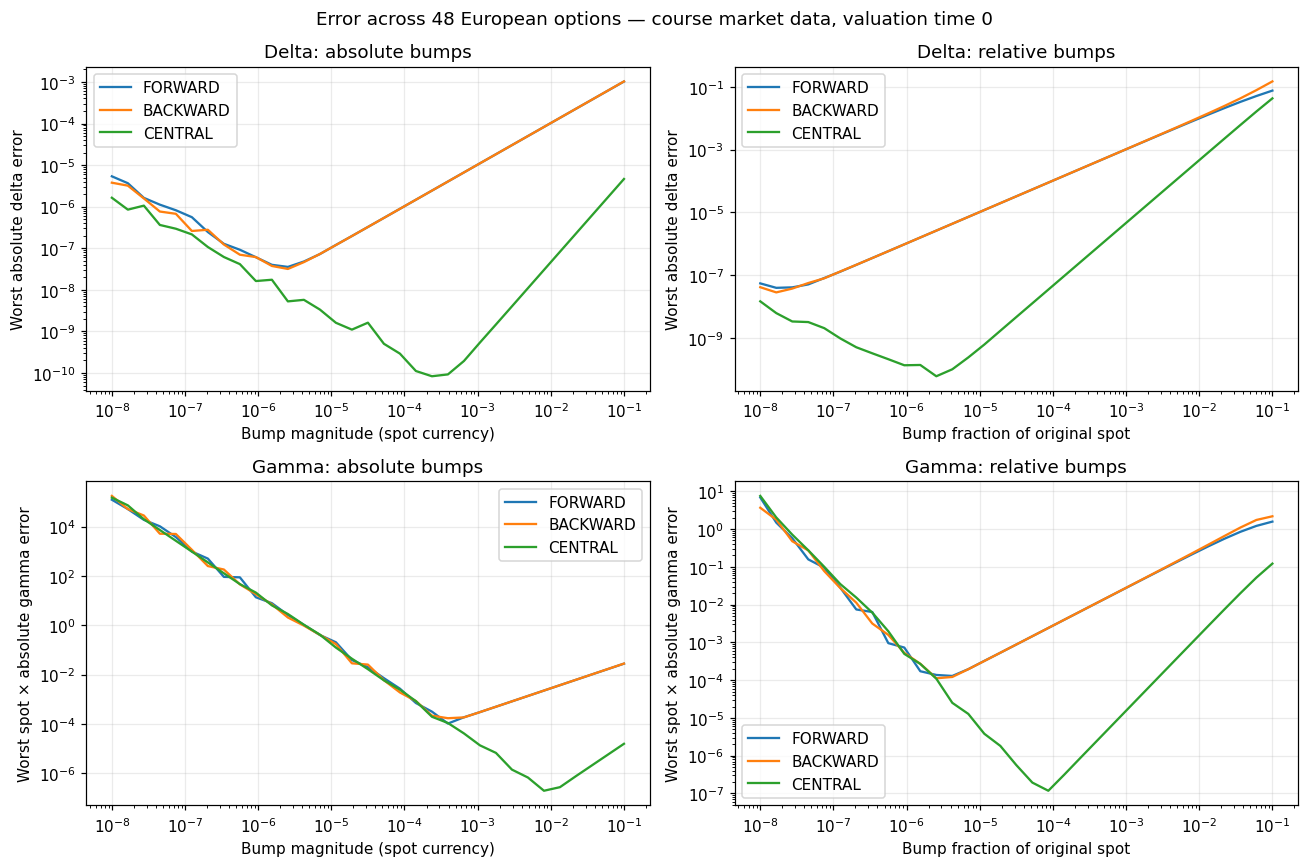

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12,8))
colors = {'FORWARD':'tab:blue', 'BACKWARD':'tab:orange', 'CENTRAL':'tab:green'}
for row, greek in enumerate(['delta','gamma']):
    for col, bump in enumerate(['ABSOLUTE','RELATIVE']):
        ax = axes[row,col]
        for scheme in FiniteDifferenceMethod:
            data = summary[(summary.greek==greek)&(summary.bump==bump)&(summary.scheme==scheme.value)]
            ax.loglog(data['size'], np.maximum(data.worst_error,1e-18), label=scheme.value, color=colors[scheme.value])
        ax.set(title=f'{greek.capitalize()}: {bump.lower()} bumps',
               xlabel='Bump magnitude (spot currency)' if bump=='ABSOLUTE' else 'Bump fraction of original spot',
               ylabel='Worst absolute delta error' if greek=='delta' else 'Worst spot × absolute gamma error')
        ax.legend()
fig.suptitle('Error across 48 European options — course market data, valuation time 0')
fig.tight_layout()
fig.savefig(output/'error_curves.png', bbox_inches='tight')
plt.show()

## Individual options and matched bump conventions
The next plot shows how the best central relative bump for this set performs on every option. Absolute and relative bumping should agree when their **effective spot increments** are equal: they are two ways to specify the same stencil, not different differentiation formulas.

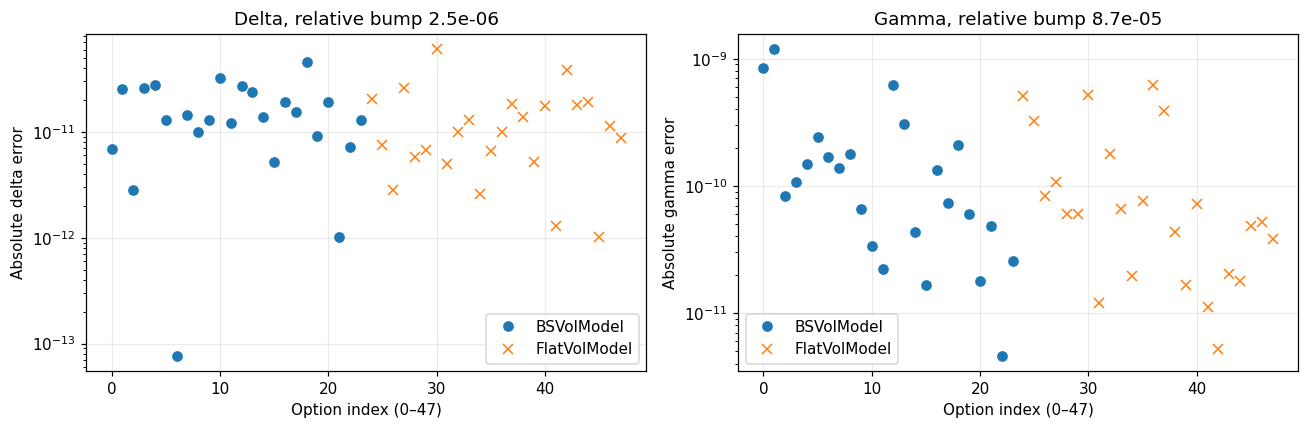

Maximum matched-convention difference (delta, gamma): [0. 0.]


In [6]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
for ax, greek in zip(axes,['delta','gamma']):
    selected = best[(best.greek==greek)&(best.scheme=='CENTRAL')&(best.bump=='RELATIVE')].iloc[0]
    data = results[(results.greek==greek)&(results.scheme=='CENTRAL')&
                   (results.bump=='RELATIVE')&(results['size']==selected['size'])]
    for model_name, marker in [('BSVolModel','o'),('FlatVolModel','x')]:
        d = data[data.model==model_name]
        ax.semilogy(d.contract, np.maximum(d.abs_error,1e-18), marker, label=model_name)
    ax.set(title=f"{greek.capitalize()}, relative bump {selected['size']:.2g}",
           xlabel='Option index (0–47)', ylabel=f'Absolute {greek} error')
    ax.legend()
fig.tight_layout()
fig.savefig(output/'individual_errors.png',bbox_inches='tight')
plt.show()
matched = []
for p in contracts:
    p.finite_difference_method = FiniteDifferenceMethod.CENTRAL
    p.relative_bump_size = 1e-4
    p.absolute_bump_size = p.relative_bump_size*p.model.spot
    p.bump_type = BumpType.RELATIVE
    relative = np.array([p.calc_delta(GreekMethod.BUMP),p.calc_gamma(GreekMethod.BUMP)])
    p.bump_type = BumpType.ABSOLUTE
    absolute = np.array([p.calc_delta(GreekMethod.BUMP),p.calc_gamma(GreekMethod.BUMP)])
    matched.append(abs(relative-absolute))
print('Maximum matched-convention difference (delta, gamma):', np.max(matched,axis=0))

## Interpretation and practical recommendation
Read the empirical optima printed below together with the curves. Central differences generally reach lower errors using larger bumps than one-sided differences. Tiny bumps amplify cancellation, especially in gamma. A relative bump automatically scales with stock price; one absolute currency increment gives different percentage shocks for different stocks. Matched effective increments give identical results.

Use central relative differences as the starting choice, with separate calibrated magnitudes for delta and gamma. The table reports the best sampled values for this particular option set; these are not universal constants. For a new portfolio, repeat a local bump sweep and look for a stable region rather than trusting a single minimum. Short-dated or sharply curved options can require smaller increments. The retained lecture default of 1% is a compatibility setting, not the optimal recommendation from this experiment.

In [7]:
for greek in ['delta','gamma']:
    row = best[(best.greek==greek)&(best.scheme=='CENTRAL')&(best.bump=='RELATIVE')].iloc[0]
    print(f"{greek}: central relative bump {row['size']:.6g} "
          f"({100*row['size']:.6g}%); worst dimensionless error {row.worst_error:.3g}")
print('One shared bump is a compromise: the two derivatives have different cancellation sensitivity.')

delta: central relative bump 2.5483e-06 (0.00025483%); worst dimensionless error 6e-11
gamma: central relative bump 8.65964e-05 (0.00865964%); worst dimensionless error 1.18e-07
One shared bump is a compromise: the two derivatives have different cancellation sensitivity.


## Validation and submission contents
`test_numerical_greeks.py` checks all six combinations against analytic Greeks under both models, call/put and long/short positions, different strikes/maturities, preservation of model state and valuation time, exact stencil points, equivalent absolute/relative shocks, put–call parity, forward Greeks, invalid bumps, and convergence orders.

Run from repository root:
```
venv_quant_course_v312/bin/python -m pytest homeworks/83019cd/assignment_4 -q
```
The notebook is executed and includes its outputs. `figures/` contains exported plots; `greek_errors.csv` contains all measurements and `optimal_bumps.csv` contains the sampled optima. All code and market inputs are local and reproducible. No additional downloaded market data are needed.